# 06 — Loopback OpenSSL 3.5.9 Verification: Self-Tests, KATs, Traces, Compatibility, Overhead & Gates

**Purpose:** Execute real loopback TLS 1.3 handshakes (`X25519` vs `X25519MLKEM768` + `ML-DSA-65`), deterministic FIPS 203/204 seed KAT vectors, per-service KMS/JWS stack checks, 11-case peer compatibility matrix, and verification gates.

**Inputs:** Git-bundled OpenSSL 3.5.9 (`127.0.0.1`, throw-away keys in temp dir) and Python `cryptography 50.0.2` (`mlkem`, `mldsa`).

**Visual Outputs:** Self-Tests, Deterministic KATs & Stack Integration (`06_selftests_kats_and_stack`), Handshake Bytes (`06_handshake_bytes`), Compatibility Matrix (`06_compatibility`), Subprocess vs In-Process Timing (`06_overhead_boxplot`), Gate Heatmap (`06_gate_heatmap`).

> **Claim & Provenance Status:** VERIFIED, TEST SCENARIO (loopback 127.0.0.1, ephemeral test keys). 3 services reach `READY` (generic loopback evidence); 3 stay `PROPOSED` due to unresolved/held findings or missing scanned files.
>
> **Scope Context:** All demo banking services in `demo_bank_app/` are **SYNTHETIC**. High-DPI figures are also archived in `assets/diagrams/member3/` and `scratch/derived/member3/figs/`.

### 06A–06C · Cryptographic Self-Tests, Deterministic Seed KAT Vectors & Service-Stack Integration

OpenSSL 3.5.9 CLI and Python `cryptography` pass round-trip `ML-KEM-768` (1088 B ct, 32 B secret) and `ML-DSA-65` (3309 B sig) checks, deterministic seed KAT SHA-256 checks (`1184 B` and `1952 B` public keys), and per-service KMS DEK wrapping (`card_vault`) + JWS signing (`auth_gateway`/`payment_signing`).

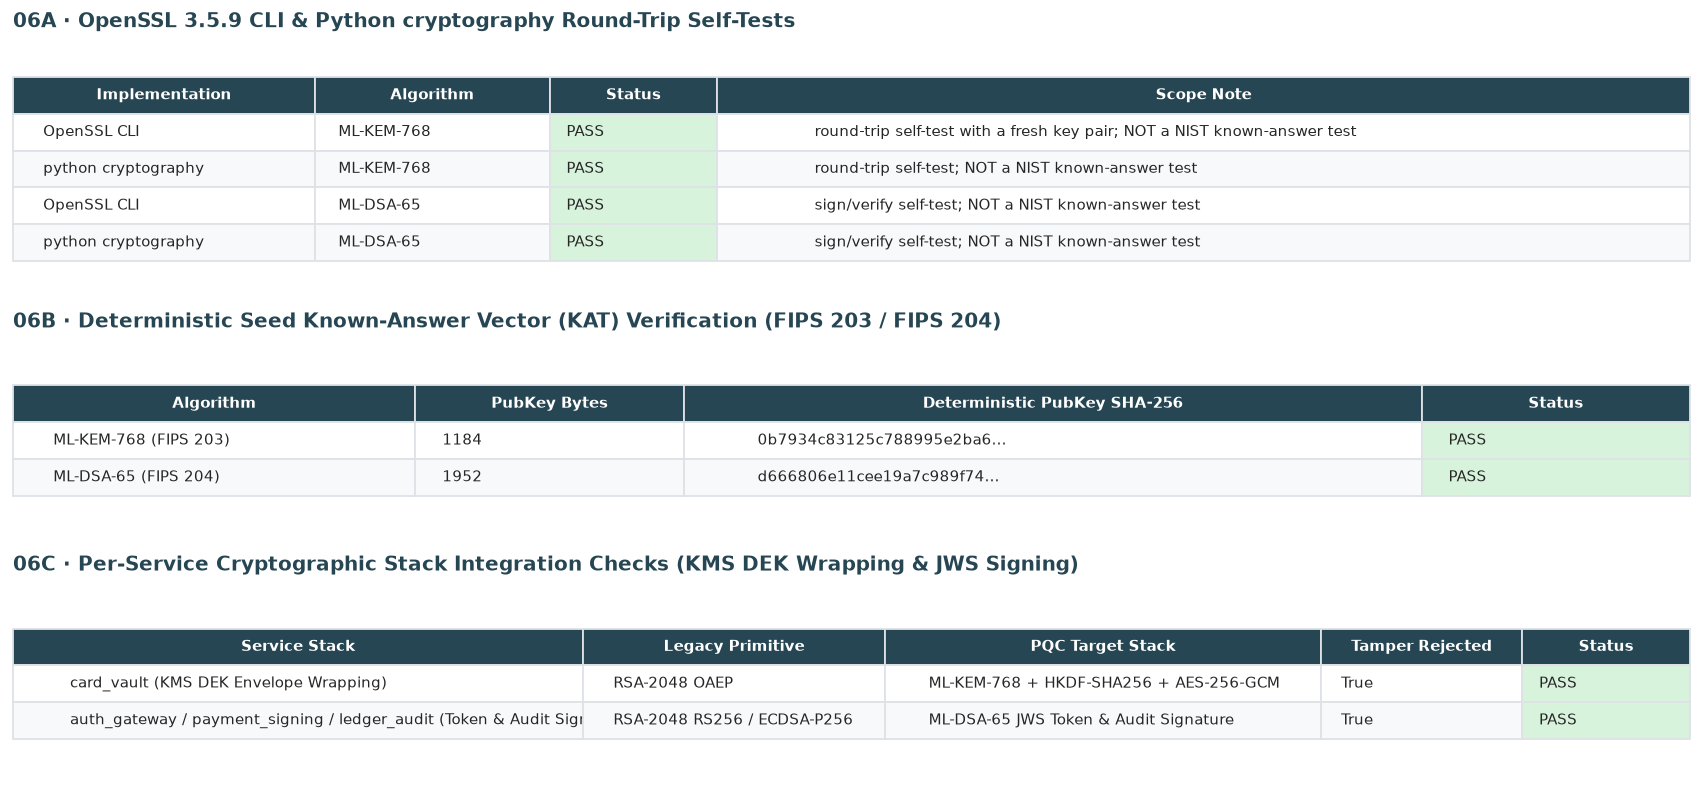

### 06D · Loopback TLS 1.3 Handshake Wire Bytes (Before vs After Hybrid PQC)

Negotiating `X25519MLKEM768` with an EC-P256 certificate adds ~1.1 kB in each direction (`757/388 B` → `1843/1564 B`), while an `ML-DSA-65` server certificate chain increases client bytes read to `10,207 B`.

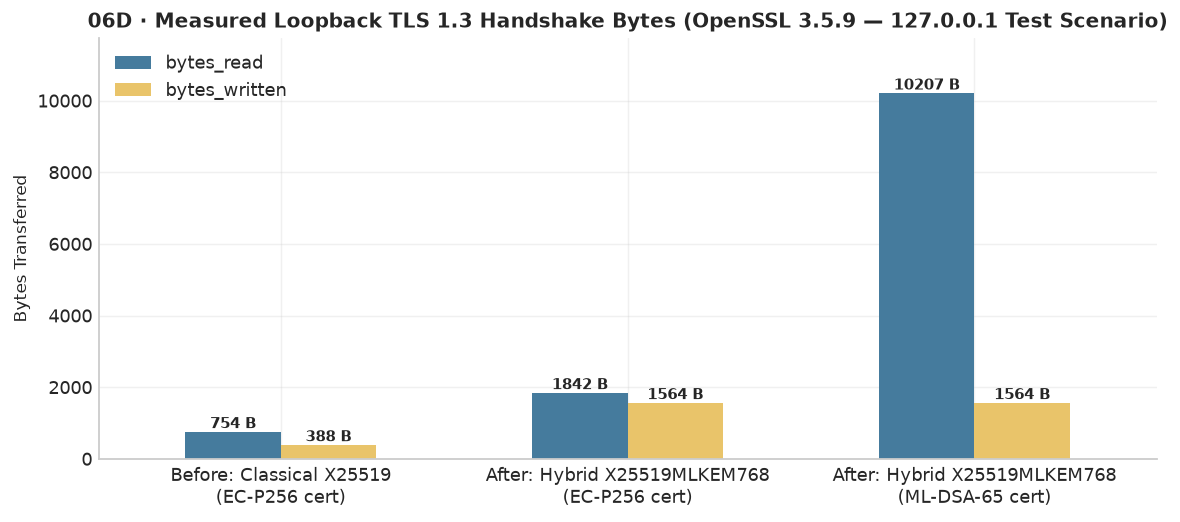

### 06E · 11-Case Peer Compatibility & Negative Rejection Matrix

All 11/11 loopback test cases match expected behaviour: 2 positive handshakes, 2 hybrid-to-classical fallbacks, and 7 negative cases (classical-only vs hybrid-required, TLS 1.2-only, group mismatch, expired cert, untrusted CA) cleanly rejected.

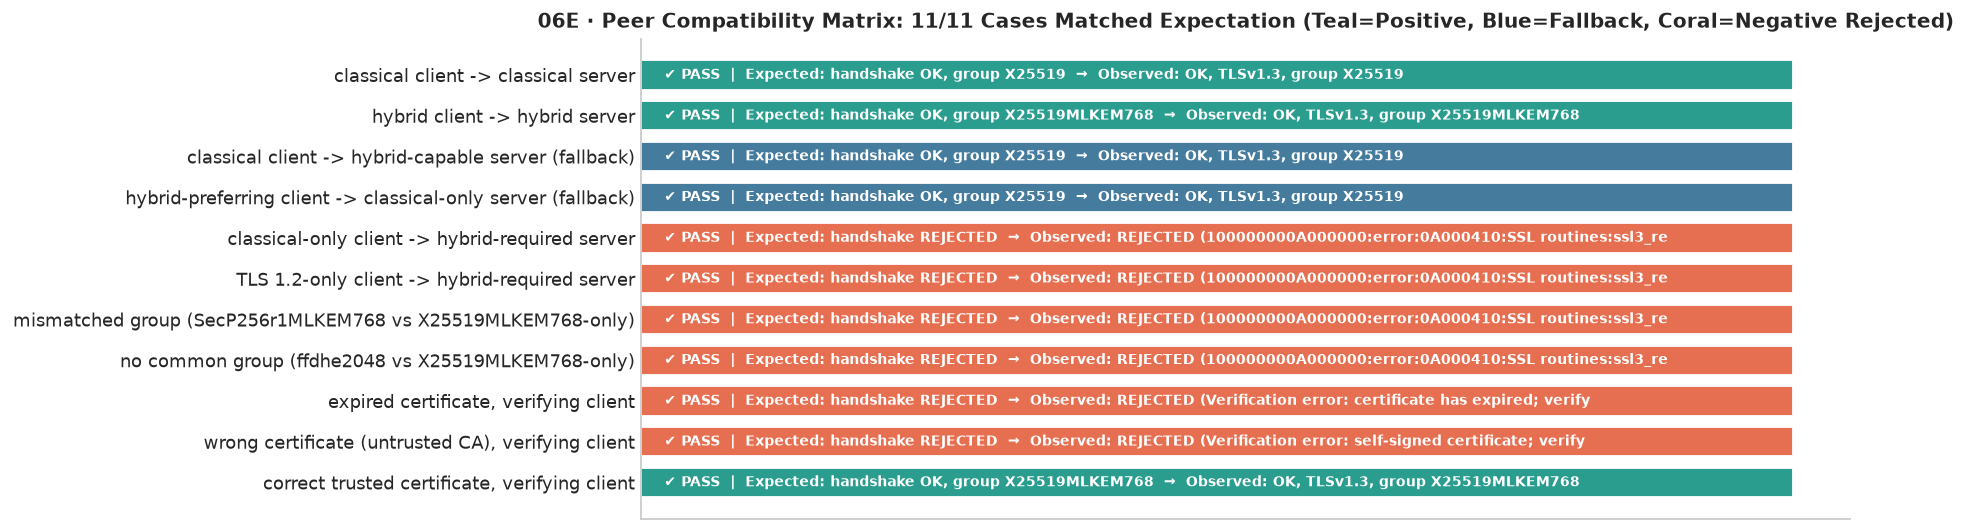

### 06F & 06G · Subprocess Handshake Wall-Clock vs Pure In-Process Primitive Timing

Left: `openssl s_client` subprocess wall time (~78–96 ms) is dominated by Windows process start-up noise. Right: pure in-process Python `cryptography` microsecond benchmarks isolate the true primitive speed (`ML-KEM-768` encap+decap and `ML-DSA-65` sign+verify).

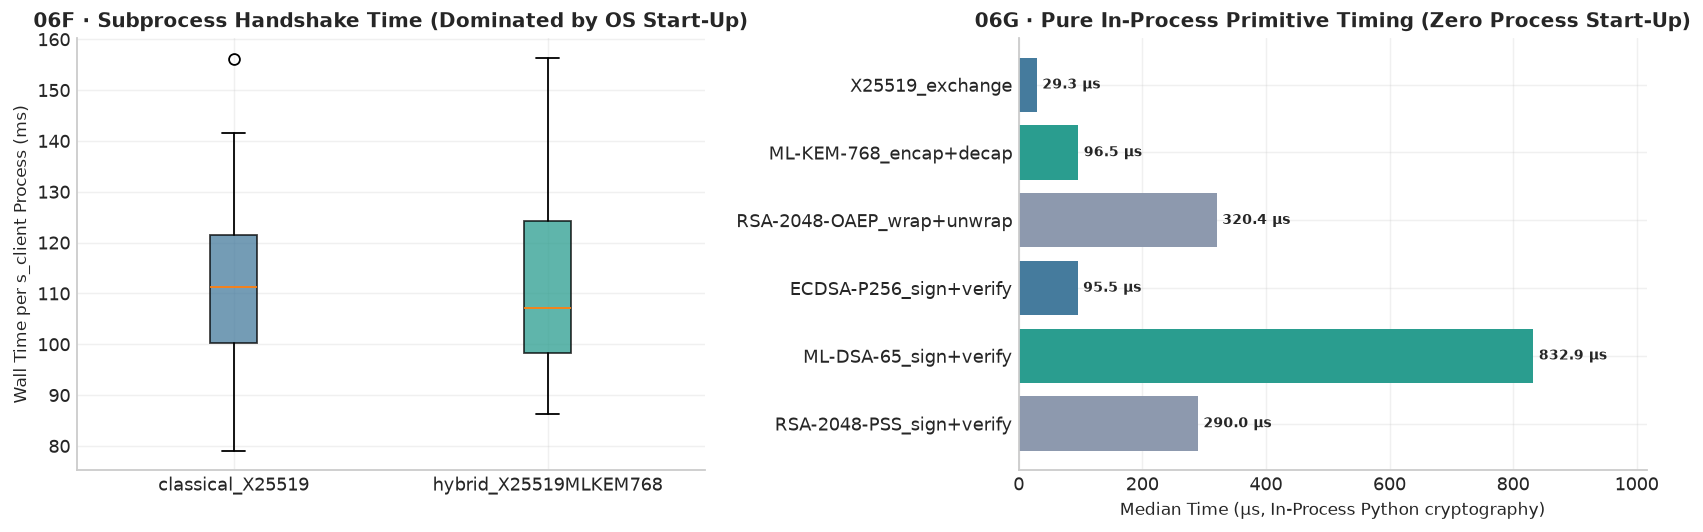

### 06H · Verification Gate Status Matrix Across All 6 Banking Services

`card_vault`, `interbank_tls`, and `payment_signing` pass all required gates (`READY`). `auth_gateway` (held unknown-purpose RSA finding) and `ledger_audit` / `settlement_batch` (`DECLARED_ONLY`) fail `purpose_resolved` and remain `PROPOSED`.

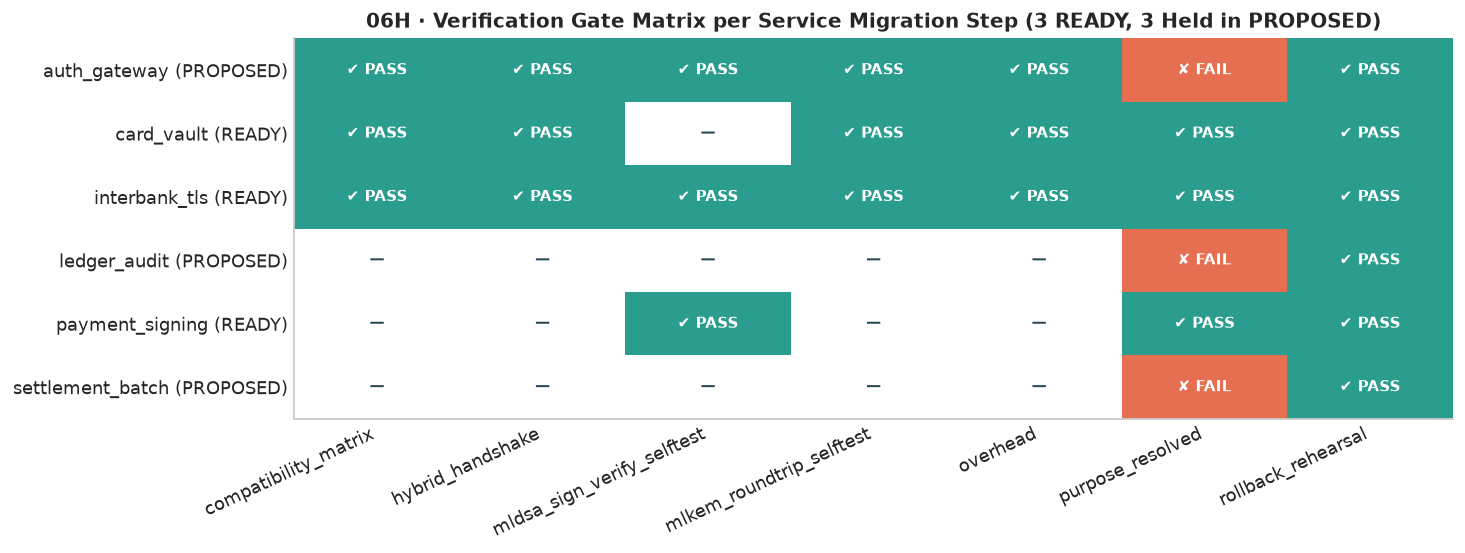